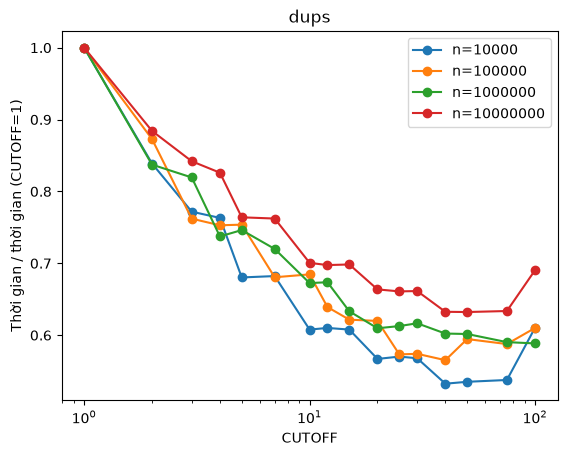

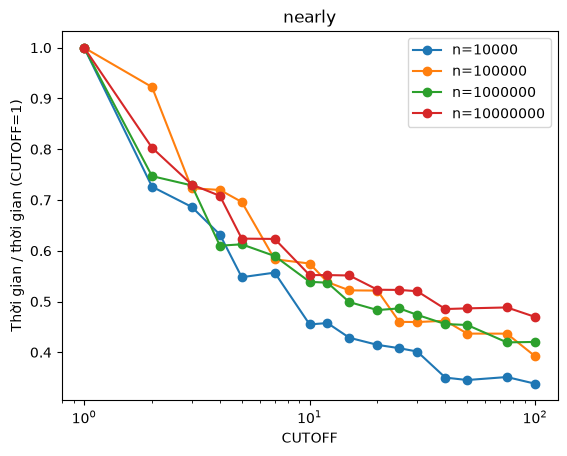

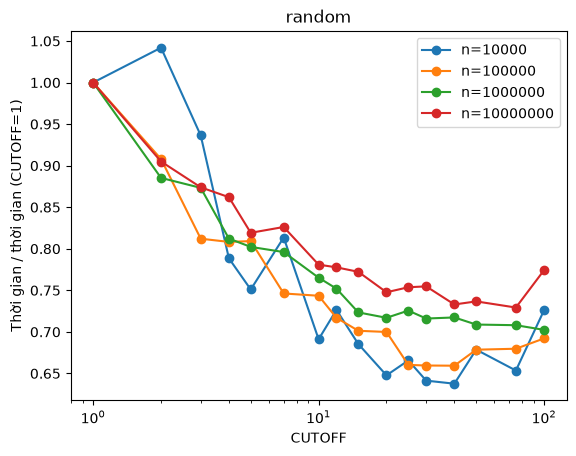

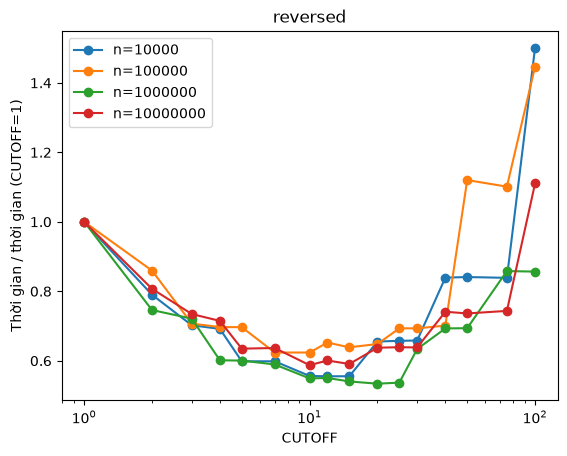

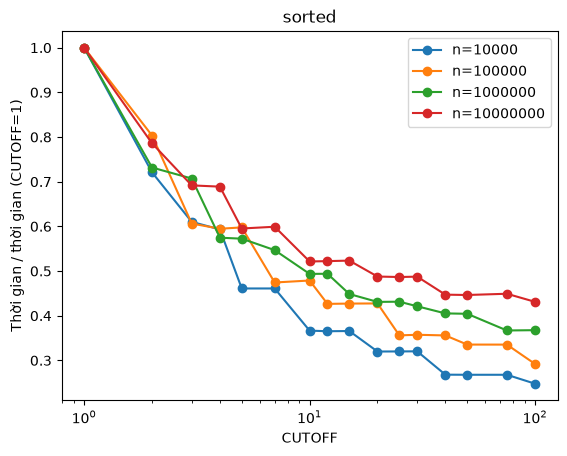

In [3]:
import pandas as pd, matplotlib.pyplot as plt
df = pd.read_csv("../results/raw.csv")
g = df.groupby(["type","n","cutoff"])["nanos"].agg(["median","mean","std","count"]).reset_index()
g["ms"] = g["median"] / 1e6
# tỉ lệ so với baseline cutoff=1
base = g[g.cutoff==1].set_index(["type","n"])["median"]
g["ratio"] = g.apply(lambda r: r["median"]/base[(r["type"],r["n"])], axis=1)

for t in g.type.unique():
    plt.figure()
    for n, sub in g[g.type==t].groupby("n"):
        plt.plot(sub.cutoff, sub.ratio, marker="o", label=f"n={n}")
    plt.xscale("log"); plt.xlabel("CUTOFF"); plt.ylabel("Thời gian / thời gian (CUTOFF=1)")
    plt.title(t); plt.legend(); plt.savefig(f"../results/{t}.png", dpi=150)